# AI preparedness and the global poorest decile

This notebook explores the IMF AI Preparedness Index (AIPI) and asks how country-level preparedness relates to where people in the global bottom decile live.

**Sources:** Data360 indicator `IMF_AI_AIPI_IX` from dataset `IMF_AI` (2023); World Bank PIP 1,000-bin distribution (2023) for the global D1 country shares. AIPI ranges from 0 to 1, with higher scores indicating greater preparedness. This is a country-level comparison; it does not measure AI access or use among D1 households, and any association is descriptive, not causal.

## 1. Import libraries

We use tools to query the data, analyze it, and create reproducible visualizations.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "dev_indicators" / "indicator_analysis_helpers.py").exists()
)
sys.path.insert(0, str(ROOT / "dev_indicators"))
from indicator_analysis_helpers import fetch_indicator, load_d1_shares

PIP_FILE = ROOT / "GlobalDist1000bins_1990_2026_20260922_2021_01_02_PROD.csv"
AIPI_YEAR = 2023

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 20)
print("Project root: repository root")

## 2. Load the data

The AIPI is queried from Data360 using dataset `IMF_AI` and indicator `IMF_AI_AIPI_IX`. We use 2023 for the comparison with the D1, the only year returned by this series in the verified query. D1 shares are calculated from PIP's 1,000-bin distribution; its population column is expressed in millions.

In [4]:
aipi_all = fetch_indicator("IMF_AI", "IMF_AI_AIPI_IX")
aipi = aipi_all.loc[aipi_all["year"].eq(AIPI_YEAR)].copy()
d1_all = load_d1_shares(PIP_FILE)
d1_2023 = d1_all.loc[d1_all["year"].eq(AIPI_YEAR)].copy()

print(f"AIPI observations: {len(aipi)} countries in {AIPI_YEAR}")
print(f"PIP D1 country observations: {len(d1_2023)} countries in {AIPI_YEAR}")
display(aipi.head())
display(d1_2023.head())

AIPI observations: 166 countries in 2023
PIP D1 country observations: 218 countries in 2023


,code,year,indicator_value,region
0,AGO,2023,0.259659,Sub-Saharan Africa
1,ALB,2023,0.526793,Europe & Central Asia
2,ARE,2023,0.628185,"Middle East, North Africa, Afghanistan & Pakistan"
3,ARG,2023,0.473809,Latin America & Caribbean
4,ARM,2023,0.492887,Europe & Central Asia


,year,code,country_population,d1_pop_people,global_d1_population,d1_country_population_pct,d1_population_share
7194,2023,ABW,0.107359,0.000966,806.37896,0.9,0.000001
7195,2023,AFG,41.454761,18.903371,806.37896,45.6,0.023442
7196,2023,AGO,36.749906,15.287961,806.37896,41.6,0.018959
7197,2023,ALB,2.414095,0.002414,806.37896,0.1,0.000003
7198,2023,AND,0.080856,0.000000,806.37896,0.0,0.000000


## 3. Inspect the data structure

We review dimensions, columns, data types, and records to confirm that the query returns one observation per country and year and that the merge uses consistent country codes.

In [5]:
print("AIPI shape:", aipi.shape)
print("AIPI columns:", aipi.columns.tolist())
print("AIPI dtypes:\n", aipi.dtypes)
print("PIP D1 shape:", d1_2023.shape)
print("PIP D1 columns:", d1_2023.columns.tolist())
display(aipi.sample(min(5, len(aipi)), random_state=42))
display(d1_2023.sample(min(5, len(d1_2023)), random_state=42))

AIPI shape: (166, 4)
AIPI columns: ['code', 'year', 'indicator_value', 'region']
AIPI dtypes:
 code                   str
year                 int64
indicator_value    float64
region                 str
dtype: object
PIP D1 shape: (218, 7)
PIP D1 columns: ['year', 'code', 'country_population', 'd1_pop_people', 'global_d1_population', 'd1_country_population_pct', 'd1_population_share']


,code,year,indicator_value,region
100,MKD,2023,0.481986,Europe & Central Asia
136,SLE,2023,0.297813,Sub-Saharan Africa
78,JPN,2023,0.733158,East Asia & Pacific
56,GHA,2023,0.425200,Sub-Saharan Africa
97,MDA,2023,0.480629,Europe & Central Asia


,year,code,country_population,d1_pop_people,global_d1_population,d1_country_population_pct,d1_population_share
7294,2023,KEN,55.339003,23.685093,806.37896,42.8,0.029372
7409,2023,ZAF,63.212384,10.556468,806.37896,16.7,0.013091
7333,2023,NAM,2.963095,0.660770,806.37896,22.3,0.000819
7372,2023,STP,0.230871,0.027935,806.37896,12.1,0.000035
7209,2023,BEN,14.111034,3.372537,806.37896,23.9,0.004182


## 4. Assess data quality and missing values

We check for missing values, duplicates, out-of-range index values, and countries that cannot be matched. The merge may contain fewer countries than either source.

In [6]:
quality = pd.Series({
    "AIPI missing values": int(aipi.isna().sum().sum()),
    "AIPI duplicate country-year rows": int(aipi.duplicated(["code", "year"]).sum()),
    "AIPI outside [0, 1]": int((~aipi["indicator_value"].between(0, 1)).sum()),
    "PIP duplicate country-year rows": int(d1_2023.duplicated(["code", "year"]).sum()),
})
d1_country_codes = set(d1_2023["code"])
aipi_country_codes = set(aipi["code"])
matched_codes = d1_country_codes & aipi_country_codes
print("Quality checks:")
display(quality.to_frame("count"))
print(f"Countries with both sources: {len(matched_codes)}")
print("AIPI-only countries:", len(aipi_country_codes - d1_country_codes))
print("PIP-only countries:", len(d1_country_codes - aipi_country_codes))

analysis = aipi.merge(d1_2023, on=["code", "year"], how="inner", validate="one_to_one")
analysis = analysis.dropna(subset=["indicator_value", "d1_country_population_pct", "d1_pop_people"])
print(f"Matched D1 population coverage: {analysis['d1_population_share'].sum():.1%}")

Quality checks:


,count
AIPI missing values,0
AIPI duplicate country-year rows,0
"AIPI outside [0, 1]",0
PIP duplicate country-year rows,0


Countries with both sources: 165
AIPI-only countries: 1
PIP-only countries: 53
Matched D1 population coverage: 94.4%


## 5. Explore variables and summary statistics

The summary describes countries, not people. The D1-population-weighted mean answers a different question from the simple country average. The calculation for AIPI below 0.3 reports both the share among matched countries and the share of the global D1; the latter is a minimum because some countries have no matched AIPI value.

In [10]:
display(aipi["indicator_value"].describe().to_frame("AIPI"))
print("Years:", sorted(aipi_all["year"].dropna().unique().tolist()))
print("Region counts:")
display(analysis["region"].value_counts(dropna=False).rename("countries").to_frame())

region_summary = (
    analysis.groupby("region", dropna=False)
    .apply(lambda group: pd.Series({
        "countries": group["code"].nunique(),
        "mean_AIPI": group["indicator_value"].mean(),
        "median_AIPI": group["indicator_value"].median(),
        "mean_D1_country_share_pct": group["d1_country_population_pct"].mean(),
        "D1_population_millions": group["d1_pop_people"].sum(),
        "D1_weighted_AIPI": np.average(group["indicator_value"], weights=group["d1_pop_people"]),
    }), include_groups=False)
    .sort_values("D1_population_millions", ascending=False)
)
display(region_summary.round(3))

AIPI_THRESHOLD = 0.3
below_threshold = analysis.loc[analysis["indicator_value"].lt(AIPI_THRESHOLD)]
d1_below_threshold_millions = below_threshold["d1_pop_people"].sum()
matched_d1_millions = analysis["d1_pop_people"].sum()
global_d1_millions = d1_2023["global_d1_population"].max()
threshold_summary = pd.Series({
    "Countries with AIPI below 0.3": below_threshold["code"].nunique(),
    "D1 population in those countries (millions)": d1_below_threshold_millions,
    "Share of matched D1 population (%)": 100 * d1_below_threshold_millions / matched_d1_millions,
    "Share of global D1 with known AIPI below 0.3 (%)": 100 * d1_below_threshold_millions / global_d1_millions,
}, name="value")
display(threshold_summary.to_frame().round(2))
print(f"D1 population without a matched AIPI value: {global_d1_millions - matched_d1_millions:.1f} million")
print("Unique AIPI years:", aipi_all["year"].nunique())
print("AIPI value range:", (aipi["indicator_value"].min(), aipi["indicator_value"].max()))

,AIPI
count,166.000000
mean,0.475427
std,0.151785
min,0.184437
25%,0.354291
50%,0.463371
75%,0.580595
max,0.800567


Years: [2023]
Region counts:


,countries
region,
Europe & Central Asia,46
Sub-Saharan Africa,43
Latin America & Caribbean,28
"Middle East, North Africa, Afghanistan & Pakistan",21
East Asia & Pacific,20
South Asia,5
North America,2


,countries,mean_AIPI,median_AIPI,mean_D1_country_share_pct,D1_population_millions,D1_weighted_AIPI
region,,,,,,
Sub-Saharan Africa,43.0,0.338,0.326,36.351,534.861,0.314
"Middle East, North Africa, Afghanistan & Pakistan",21.0,0.444,0.429,6.833,85.382,0.329
South Asia,5.0,0.421,0.436,2.760,58.363,0.475
East Asia & Pacific,20.0,0.546,0.507,6.895,45.790,0.459
Latin America & Caribbean,28.0,0.435,0.435,4.829,28.745,0.428
Europe & Central Asia,46.0,0.610,0.609,0.752,4.133,0.583
North America,2.0,0.742,0.742,0.700,4.122,0.770


,value
Countries with AIPI below 0.3,21.00
D1 population in those countries (millions),266.64
Share of matched D1 population (%),35.02
Share of global D1 with known AIPI below 0.3 (%),33.07


D1 population without a matched AIPI value: 45.0 million
Unique AIPI years: 1
AIPI value range: (np.float64(0.184437), np.float64(0.800567))


## 6. Visualize distributions and relationships

The charts show the distribution across countries and the descriptive relationship between AIPI and the global D1. Each point's size represents the number of people in the global D1 who live in that country.

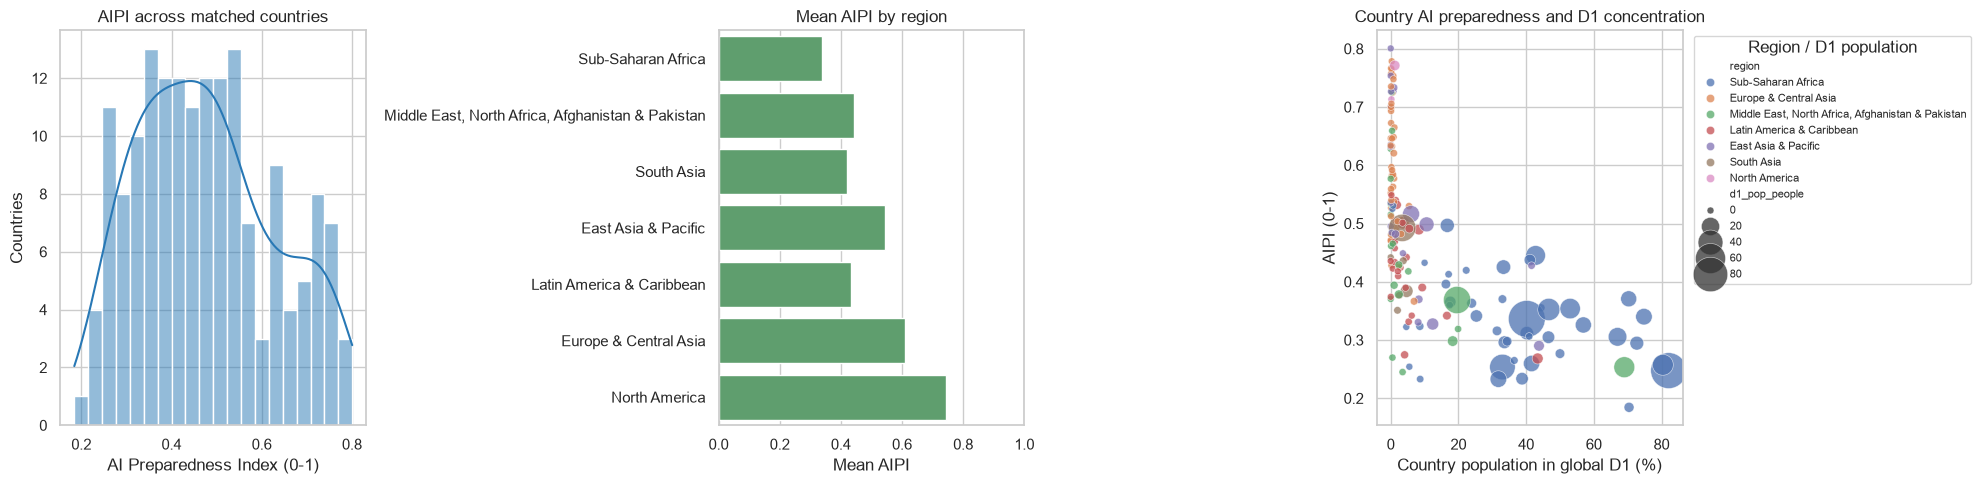

Country-level correlations across 165 matched countries (descriptive, not causal):


,correlation
Pearson (linear association),-0.606588
Spearman (rank association),-0.752342


,countries,D1_population_millions,share_of_covered_D1_pct
aipi_quartile,,,
Q1 lowest AIPI,42,506.86,66.57
Q2,41,138.73,18.22
Q3,41,107.81,14.16
Q4 highest AIPI,41,7.99,1.05


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(data=analysis, x="indicator_value", bins=20, kde=True, ax=axes[0], color="#2878B5")
axes[0].set(title="AIPI across matched countries", xlabel="AI Preparedness Index (0-1)", ylabel="Countries")

region_order = region_summary.index.tolist()
sns.barplot(data=analysis, x="indicator_value", y="region", order=region_order, estimator="mean", errorbar=None, ax=axes[1], color="#55A868")
axes[1].set(title="Mean AIPI by region", xlabel="Mean AIPI", ylabel="")
axes[1].set_xlim(0, 1)

sns.scatterplot(data=analysis, x="d1_country_population_pct", y="indicator_value", hue="region", size="d1_pop_people", sizes=(25, 700), alpha=0.75, ax=axes[2])
axes[2].set(title="Country AI preparedness and D1 concentration", xlabel="Country population in global D1 (%)", ylabel="AIPI (0-1)")
axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, title="Region / D1 population")
plt.tight_layout()
plt.show()

pearson = analysis["indicator_value"].corr(analysis["d1_country_population_pct"], method="pearson")
spearman = analysis["indicator_value"].rank().corr(analysis["d1_country_population_pct"].rank(), method="pearson")
correlations = pd.Series({"Pearson (linear association)": pearson, "Spearman (rank association)": spearman}, name="correlation")
print(f"Country-level correlations across {len(analysis)} matched countries (descriptive, not causal):")
display(correlations.to_frame())

analysis["aipi_quartile"] = pd.qcut(analysis["indicator_value"], q=4, labels=["Q1 lowest AIPI", "Q2", "Q3", "Q4 highest AIPI"])
quartile_summary = analysis.groupby("aipi_quartile", observed=False).agg(countries=("code", "nunique"), D1_population_millions=("d1_pop_people", "sum"))
quartile_summary["share_of_covered_D1_pct"] = 100 * quartile_summary["D1_population_millions"] / analysis["d1_pop_people"].sum()
display(quartile_summary.round(2))

**Interpretation:** Do countries with more people in the global D1 have different AIPI scores? Does the answer change when countries are weighted by the number of people in the D1 who live there? This is a descriptive comparison, depends on data coverage, and does not show that AI preparedness causes higher or lower incomes.

## 7. Save the prepared data

The CSV includes only countries present in both sources and the fields needed to reproduce the analysis. Running this cell saves a copy to `data/processed/`.

In [ ]:
prepared = analysis[[
    "code", "region", "year", "indicator_value",
    "d1_country_population_pct", "d1_pop_people", "d1_population_share",
]].rename(columns={
    "indicator_value": "aipi",
    "d1_country_population_pct": "country_population_in_global_d1_pct",
    "d1_pop_people": "population_from_country_in_global_d1_millions",
    "d1_population_share": "share_of_global_d1_population",
})
output_path = ROOT / "data" / "processed" / "ai_preparedness_pip_2023.csv"
prepared.to_csv(output_path, index=False)
print(f"Saved {len(prepared)} matched country rows to {output_path.relative_to(ROOT)}")